**E-Commerce Customer Analytics**

**Project Type:** Data Science and Machine Learning

**Contribution:** Individual
Project Summary

**Name:** Shilpi Bhakat

This project analyses e-commerce transaction records to explore purchasing patterns, product prices, discounts, payment methods and sales trends. It applies Linear Regression for spending estimation, KNN for finding similar products, and K-Means for grouping records based on transaction-derived features.

**Problem Statement**

E-commerce businesses need to understand transaction patterns and product preferences to support better business decisions. This project uses the available transaction data to summarize sales, estimate spending, identify similar products and explore groups within the records.

**Note:** The uploaded dataset contains transaction-level fields only. It does not include customer demographics, browsing activity, product ratings, or non-purchase records. The limitations of the dataset for purchase-probability prediction and repeat-customer analysis are explained in the notebook.

1. COLLECT DATA

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


Pandas and NumPy are used for data handling and numerical calculations. Matplotlib, Seaborn, and Scikit-learn are used for visualization and machine learning.

In [ ]:
#Load the dataset
df = pd.read_csv("/content/ecommerce_dataset_updated.csv")

The dataset contains 3,660 records and 8 columns, including user IDs, product IDs, categories, prices, discounts, payment methods, and purchase dates. It is used to analyse purchasing patterns, customer spending, and product preferences.

**Dataset suitability and limitations**

The dataset contains 3,660 completed transactions and 8 columns. It has no missing values or duplicate rows. Every User_ID and Product_ID occurs only once.
- **Not available:** customer demographics, browsing history, product ratings, and non-purchase records.
- **Spending forecast:** one transaction per user means there is no customer purchase history from which to learn future spending. The regression model below therefore estimates a transaction's final price; it does not claim to forecast future customer spending.
- **Purchase probability:** Logistic Regression cannot be trained because the dataset has no purchase/non-purchase target labels.
- **KNN:** recommendations are based on similar transaction/product attributes, not individual customer preferences or ratings.
- **Segmentation:** the three groups describe the value/discount profile of each recorded transaction. They cannot reliably represent repeat, loyal, or occasional customer behaviour.

These are limitations of the supplied data, not coding errors. Additional browsing, product-catalogue, and non-purchase data would be needed to fully implement those functions.

In [ ]:
#First 5 rows
df.head()

,User_ID,Product_ID,Category,Price (Rs.),Discount (%),Final_Price(Rs.),Payment_Method,Purchase_Date
0,337c166f,f414122f-e,Sports,36.53,15,31.05,Net Banking,12-11-2024
1,d38a19bf,fde50f9c-5,Clothing,232.79,20,186.23,Net Banking,09-02-2024
2,d7f5f0b0,0d96fc90-3,Sports,317.02,25,237.76,Credit Card,01-09-2024
3,395d4994,964fc44b-d,Toys,173.19,25,129.89,UPI,01-04-2024
4,a83c145c,d70e2fc6-e,Beauty,244.80,20,195.84,Net Banking,27-09-2024


In [ ]:
#Shape of the dataset
df.shape

(3660, 8)

In [ ]:
#Dataset Column names
df.columns


Index(['User_ID', 'Product_ID', 'Category', 'Price (Rs.)', 'Discount (%)',
       'Final_Price(Rs.)', 'Payment_Method', 'Purchase_Date'],
      dtype='object')

In [ ]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3660 entries, 0 to 3659
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           3660 non-null   object 
 1   Product_ID        3660 non-null   object 
 2   Category          3660 non-null   object 
 3   Price (Rs.)       3660 non-null   float64
 4   Discount (%)      3660 non-null   int64  
 5   Final_Price(Rs.)  3660 non-null   float64
 6   Payment_Method    3660 non-null   object 
 7   Purchase_Date     3660 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 228.9+ KB


In [ ]:
# Describe numerical columns
df.describe()

,Price (Rs.),Discount (%),Final_Price(Rs.)
count,3660.000000,3660.000000,3660.000000
mean,254.800675,18.825137,206.906579
std,141.682621,14.731338,122.687844
min,10.090000,0.000000,5.890000
25%,134.012500,5.000000,104.512500
50%,253.845000,15.000000,199.185000
75%,377.595000,25.000000,304.117500
max,499.960000,50.000000,496.820000


2. PREPROCESS DATA

In [ ]:
# Check and handle missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
User_ID             0
Product_ID          0
Category            0
Price (Rs.)         0
Discount (%)        0
Final_Price(Rs.)    0
Payment_Method      0
Purchase_Date       0
dtype: int64

Missing values after cleaning:
User_ID             0
Product_ID          0
Category            0
Price (Rs.)         0
Discount (%)        0
Final_Price(Rs.)    0
Payment_Method      0
Purchase_Date       0
dtype: int64


In [ ]:
# Remove duplicate records
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", duplicate_count)
print("Dataset shape after cleaning:", df.shape)

Duplicate rows removed: 0
Dataset shape after cleaning: (3660, 8)


In [ ]:
df["Purchase_Date"] = pd.to_datetime(
    df["Purchase_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(df["Purchase_Date"].dtype)

datetime64[ns]


3.ANALYZE DATA — EDA

In [ ]:
# Number of purchases in each category
category_count = df['Category'].value_counts()
print(category_count)

Category
Home & Kitchen    549
Books             534
Clothing          531
Toys              523
Sports            520
Beauty            505
Electronics       498
Name: count, dtype: int64


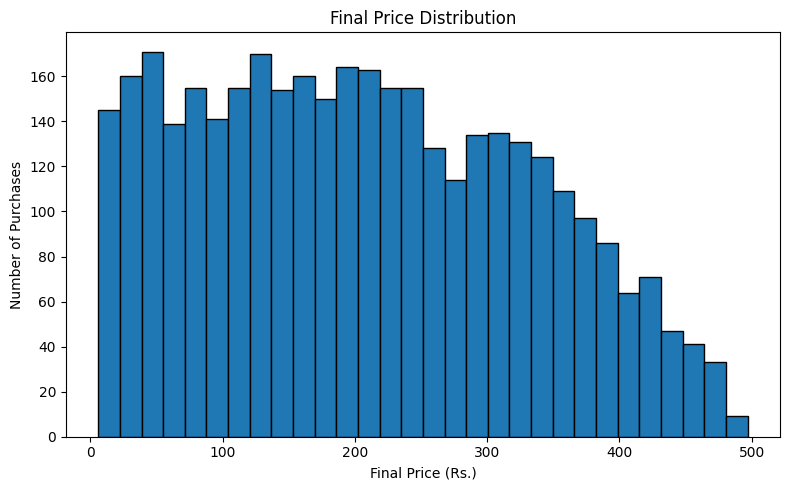

In [ ]:
# Final Price Distribution
plt.figure(figsize=(8,5))

plt.hist(
    df["Final_Price(Rs.)"],
    bins=30,
    edgecolor="black"
)

plt.title("Final Price Distribution")
plt.xlabel("Final Price (Rs.)")
plt.ylabel("Number of Purchases")
plt.tight_layout()
plt.show()

Purpose: This histogram shows the distribution of final product prices after discounts, helping you understand customer spending patterns.

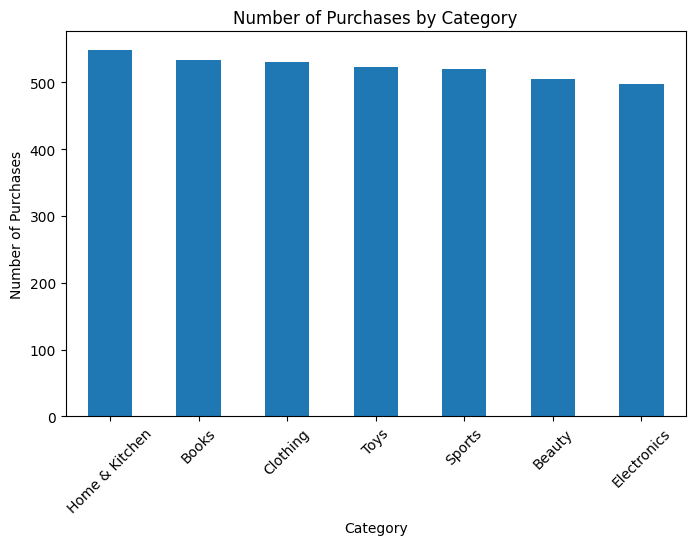

In [ ]:
# Purchases by category
category_count.plot(kind='bar', figsize=(8, 5))
plt.title('Number of Purchases by Category')
plt.xlabel('Category')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Total sales by category
category_sales = df.groupby('Category')['Final_Price(Rs.)'].sum()
print(category_sales)

Category
Beauty            104215.10
Books             111149.35
Clothing          115314.84
Electronics       100462.23
Home & Kitchen    110328.08
Sports            108518.79
Toys              107289.69
Name: Final_Price(Rs.), dtype: float64


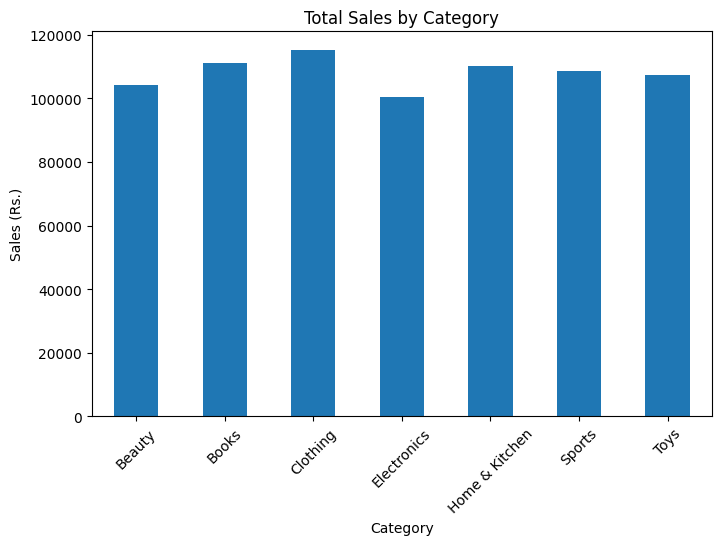

In [ ]:
# Sales by category
category_sales.plot(kind='bar', figsize=(8, 5))
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Sales (Rs.)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Number of purchases by payment method
payment_count = df['Payment_Method'].value_counts()
print(payment_count)

Payment_Method
Credit Card         760
UPI                 757
Debit Card          731
Net Banking         716
Cash on Delivery    696
Name: count, dtype: int64


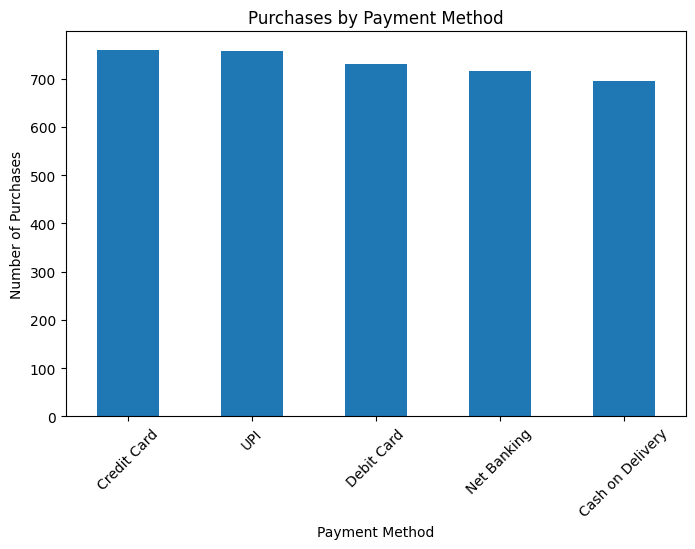

In [ ]:
# Payment method distribution
payment_count.plot(kind='bar', figsize=(8, 5))
plt.title('Purchases by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Purchases')
plt.xticks(rotation=45)
plt.show()

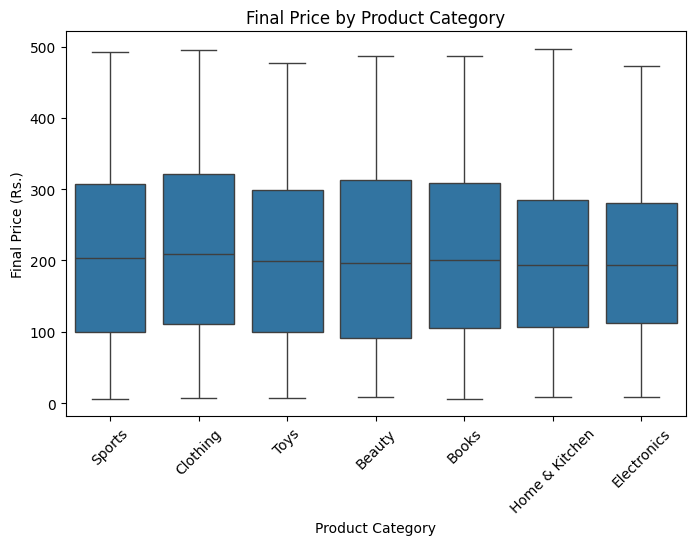

In [ ]:
# Final Price by Product Category

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Category",
    y="Final_Price(Rs.)"
)

plt.title("Final Price by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Final Price (Rs.)")
plt.xticks(rotation=45)

plt.show()

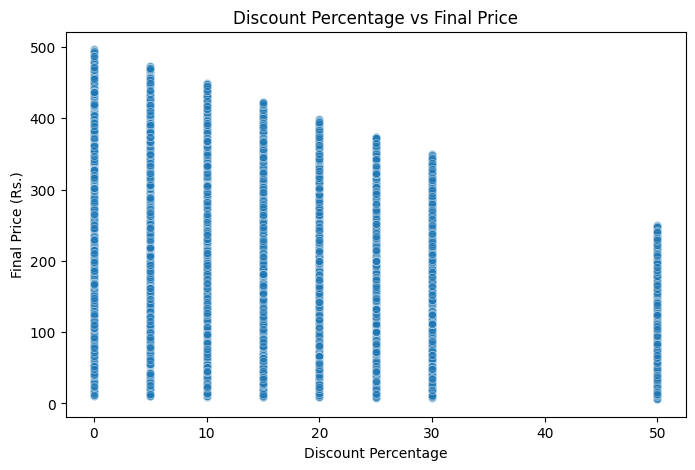

In [ ]:
# Discount Percentage vs Final Price

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Discount (%)",
    y="Final_Price(Rs.)",
    alpha=0.5
)

plt.title("Discount Percentage vs Final Price")
plt.xlabel("Discount Percentage")
plt.ylabel("Final Price (Rs.)")

plt.show()

In [ ]:
# Monthly sales
df['Month'] = df['Purchase_Date'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Month')['Final_Price(Rs.)'].sum()
print(monthly_sales)

Month
2024-01    69009.43
2024-02    69186.34
2024-03    71325.40
2024-04    74365.13
2024-05    68837.25
2024-06    64256.66
2024-07    72798.23
2024-08    71506.96
2024-09    68043.09
2024-10    76034.51
2024-11    51915.08
Name: Final_Price(Rs.), dtype: float64


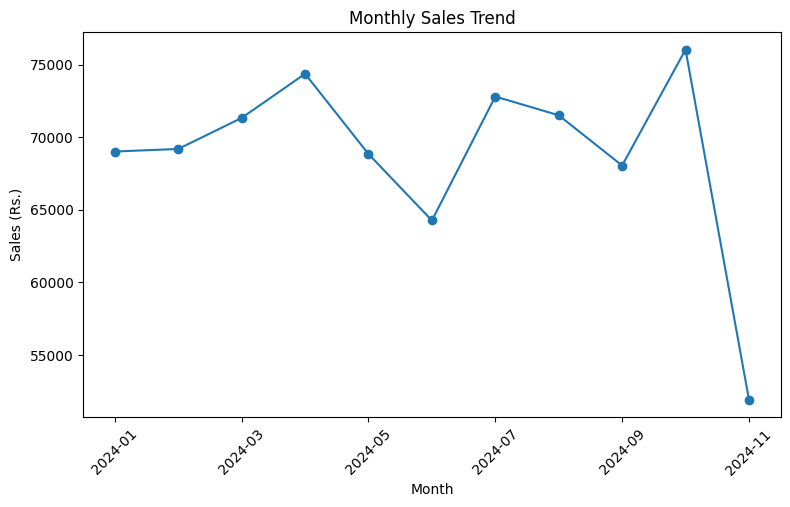

In [ ]:
# Monthly sales trend
monthly_sales.plot(kind='line', marker='o', figsize=(9, 5))
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales (Rs.)')
plt.xticks(rotation=45)
plt.show()

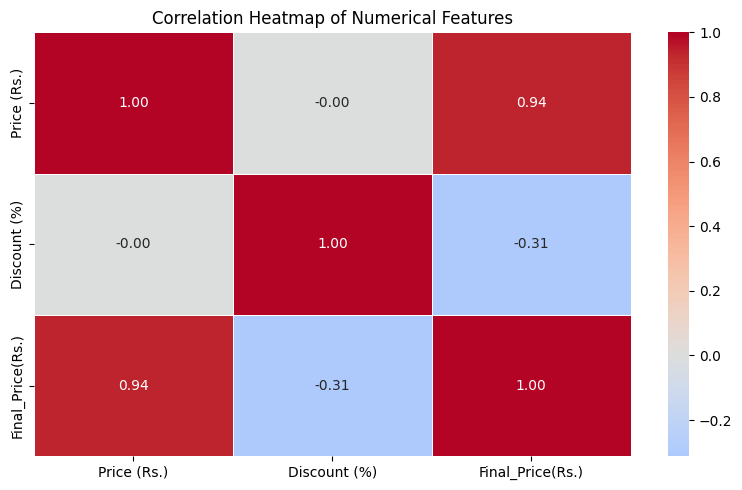

In [ ]:
# Select Numerical Columns for Correlation

corr_columns = [
    "Price (Rs.)",
    "Discount (%)",
    "Final_Price(Rs.)"
]

corr_df = df[corr_columns]

plt.figure(figsize=(8, 5))

sns.heatmap(
    corr_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.show()

Purpose: Shows the correlation between product price, discount percentage, and final price.

**LINEAR REGRESSION — TRANSACTION VALUE ESTIMATION**

The available data cannot support a future customer-spending forecast because each user has only one transaction. This model instead estimates the final price of a recorded transaction from its product and transaction attributes.

In [ ]:
# Prepare transaction-level data
model_df = df.copy()
model_df["Month"] = model_df["Purchase_Date"].dt.month

model_features = [
    "Price (Rs.)", "Discount (%)", "Category", "Payment_Method", "Month"
]
X_lr = model_df[model_features]
y_lr = model_df["Final_Price(Rs.)"]

print("Transactions available for modelling:", len(model_df))
print("Input features:", model_features)

Transactions available for modelling: 3660
Input features: ['Price (Rs.)', 'Discount (%)', 'Category', 'Payment_Method', 'Month']


Purpose: Uses price, discount, category, payment method and purchase month to estimate the final transaction price. This is not a future customer-spending forecast.

In [ ]:
# Check modelling data
print("Feature shape:", X_lr.shape)
print("Target shape:", y_lr.shape)
print("Target: Final transaction price (Rs.)")

Feature shape: (3660, 5)
Target shape: (3660,)
Target: Final transaction price (Rs.)


In [ ]:
# Split the data chronologically: earlier transactions for training, latest transactions for testing
ordered_index = model_df["Purchase_Date"].sort_values().index
split_point = int(len(ordered_index) * 0.80)

train_index = ordered_index[:split_point]
test_index = ordered_index[split_point:]

X_train_lr, X_test_lr = X_lr.loc[train_index], X_lr.loc[test_index]
y_train_lr, y_test_lr = y_lr.loc[train_index], y_lr.loc[test_index]

print("Training transactions:", len(X_train_lr))
print("Testing transactions:", len(X_test_lr))

Training transactions: 2928
Testing transactions: 732


In [ ]:
# Preprocess numeric and categorical features without data leakage
numeric_features = ["Price (Rs.)", "Discount (%)", "Month"]
categorical_features = ["Category", "Payment_Method"]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [ ]:
# Build a Ridge Regression pipeline
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

print("Regression pipeline ready for optimization.")

Regression pipeline ready for optimization.


In [ ]:
# Tune Ridge regularization using 5-fold cross-validation on training data
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train_lr, y_train_lr)
best_ridge_model = ridge_search.best_estimator_

print("Best parameters:", ridge_search.best_params_)
print("Best CV MAE (Rs.):", round(-ridge_search.best_score_, 2))

Best parameters: {'model__alpha': 0.01}
Best CV MAE (Rs.): 14.54


In [ ]:
# Evaluate the optimized model on the untouched test set
y_pred = best_ridge_model.predict(X_test_lr)

mae = mean_absolute_error(y_test_lr, y_pred)
mse = mean_squared_error(y_test_lr, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_lr, y_pred)

print("Transaction Price Estimation Results")
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

Transaction Price Estimation Results
MAE : 14.73
MSE : 447.12
RMSE: 21.15
R²  : 0.9701


The test metrics measure how closely the model estimates final transaction prices for the held-out, later-dated records. Since final price is strongly determined by price and discount, a good score does not prove that the model can forecast future customer spending.

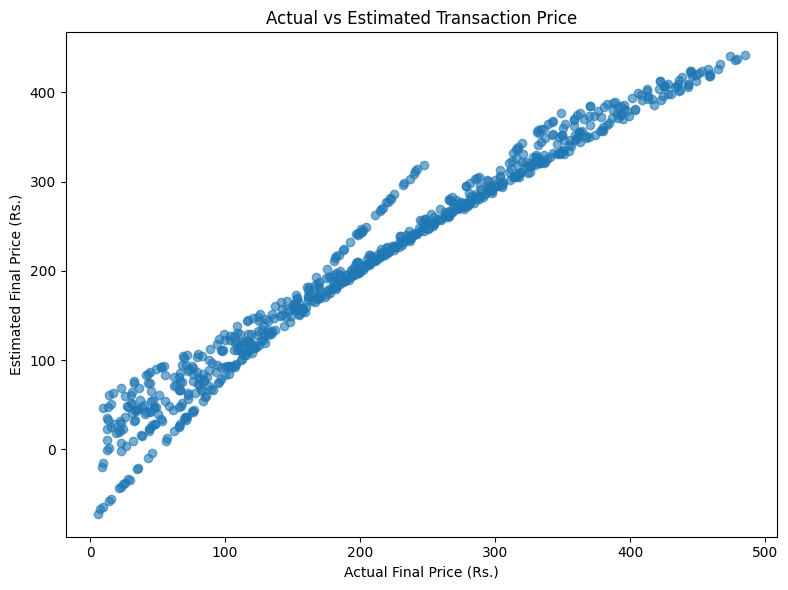

In [ ]:
# Compare actual and estimated transaction prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test_lr, y_pred, alpha=0.6)
plt.xlabel("Actual Final Price (Rs.)")
plt.ylabel("Estimated Final Price (Rs.)")
plt.title("Actual vs Estimated Transaction Price")
plt.tight_layout()
plt.show()

**KNN — SIMILAR PRODUCT/TRANSACTION RECOMMENDATION**

KNN finds records with similar category, price, discount and final-price attributes. Because each Product_ID occurs once and there are no ratings or customer preference histories, this is a similar-item demonstration rather than a personalised recommendation system.

Purpose: Prepares transaction/product records and their available attributes for nearest-neighbour similarity search.

In [ ]:
# Create Product-Level Dataset
product_df = df[
    [
        "Product_ID",
        "Category",
        "Price (Rs.)",
        "Discount (%)",
        "Final_Price(Rs.)"
    ]
].drop_duplicates(
    subset="Product_ID"
).reset_index(drop=True)

# One-Hot Encoding
product_encoded = pd.get_dummies(
    product_df,
    columns=["Category"],
    dtype=int
)

# Select KNN Features
knn_features = product_encoded.drop(
    columns=["Product_ID"]
)

# Feature Scaling
knn_scaler = StandardScaler()

knn_scaled = knn_scaler.fit_transform(knn_features)

In [ ]:
# Train KNN Recommendation Model
knn_model = NearestNeighbors(
    n_neighbors=6,
    metric="euclidean"
)

knn_model.fit(knn_scaled)

print("KNN recommendation model trained!")

KNN recommendation model trained!


In [ ]:
# Recommend similar product/transaction records
def recommend_products(product_id, n=5):
    if product_id not in product_df["Product_ID"].values:
        print("Product ID not found.")
        return None

    product_index = product_df.index[product_df["Product_ID"] == product_id][0]
    n = min(n, len(product_df) - 1)

    distances, indices = knn_model.kneighbors(
        knn_scaled[product_index].reshape(1, -1),
        n_neighbors=n + 1
    )

    result_indices = [i for i in indices[0] if i != product_index][:n]
    result = product_df.iloc[result_indices].copy()
    result["similarity_distance"] = distances[0][:len(result_indices)]
    return result

In [ ]:
# Select the first product ID from the product dataset
sample_product_id = product_df["Product_ID"].iloc[0]

# Display the selected product ID
print("Selected Product:", sample_product_id)

# Generate and display 5 similar product recommendations
recommend_products(
    sample_product_id,
    n=5
)

Selected Product: f414122f-e


,Product_ID,Category,Price (Rs.),Discount (%),Final_Price(Rs.),similarity_distance
165,8d276b60-e,Sports,41.61,15,35.37,0.000000
1331,5e4309df-9,Sports,27.03,15,22.98,0.050260
1410,3ad00ebe-5,Sports,25.95,15,22.06,0.093941
3311,9e1cec60-9,Sports,50.88,15,43.25,0.104635
2740,c355955a-7,Sports,61.67,15,52.42,0.141957


**K-MEANS — TRANSACTION VALUE SEGMENTATION**

Each user has one recorded transaction. Therefore, the clusters are interpreted as Premium, Regular and Occasional transaction-value groups, not as proven customer loyalty or purchase-frequency segments.

In [ ]:
# Build one record per user and select transaction-derived clustering features
customer_df = df.groupby("User_ID").agg(
    total_spending=("Final_Price(Rs.)", "sum"),
    total_purchases=("Product_ID", "count"),
    avg_product_price=("Price (Rs.)", "mean"),
    avg_discount=("Discount (%)", "mean")
).reset_index()

cluster_features = customer_df[
    ["total_spending", "avg_product_price", "avg_discount"]
]

print("User records:", len(customer_df))
print("Purchases per user (unique values):",
      sorted(customer_df["total_purchases"].unique()))

User records: 3660
Purchases per user (unique values): [np.int64(1)]


In [ ]:
# Initialize StandardScaler for Feature Scaling
cluster_scaler = StandardScaler()

# Scale customer features for K-Means clustering
cluster_scaled = cluster_scaler.fit_transform(
    cluster_features
)

In [ ]:
# Initialize K-Means Clustering Model with 3 Clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign each customer to a cluster
customer_df["cluster"] = kmeans.fit_predict(
    cluster_scaled
)

# Display the first five customer records with cluster labels
customer_df.head()

,User_ID,total_spending,total_purchases,avg_product_price,avg_discount,cluster
0,001ae40d,345.93,1,432.41,20.0,1
1,00209791,10.32,1,12.14,15.0,0
2,0021e458,123.51,1,145.31,15.0,0
3,00333c7a,8.65,1,11.54,25.0,0
4,00390cf5,96.32,1,137.60,30.0,0


In [ ]:
# Display the Number of Customers in Each Cluster
print(
    customer_df["cluster"].value_counts()
)

cluster
1    1529
0    1489
2     642
Name: count, dtype: int64


In [ ]:
# Summarize each transaction-value cluster
cluster_summary = customer_df.groupby("cluster")[
    ["total_spending", "avg_product_price", "avg_discount"]
].mean()

display(cluster_summary)

,total_spending,avg_product_price,avg_discount
cluster,,,
0,107.143499,124.851625,14.382136
1,329.028038,379.768842,12.972531
2,147.441651,258.566729,43.068536


In [ ]:
# Name the three transaction-value groups by average spending
cluster_order = (
    cluster_summary["total_spending"]
    .sort_values(ascending=False)
    .index
)

segment_names = ["Premium", "Regular", "Occasional"]
segment_map = dict(zip(cluster_order, segment_names))
print("Cluster-to-segment mapping:", segment_map)

Cluster-to-segment mapping: {1: 'Premium', 2: 'Regular', 0: 'Occasional'}


In [ ]:
# Assign Customer Segment Names Using Cluster Mapping
customer_df["customer_segment"] = customer_df["cluster"].map(segment_map)

# Display Customer Details and Their Segments
customer_df[
    [
        "User_ID",
        "total_spending",
        "total_purchases",
        "cluster",
        "customer_segment"
    ]
].head(20)

,User_ID,total_spending,total_purchases,cluster,customer_segment
0,001ae40d,345.93,1,1,Premium
1,00209791,10.32,1,0,Occasional
2,0021e458,123.51,1,0,Occasional
3,00333c7a,8.65,1,0,Occasional
4,00390cf5,96.32,1,0,Occasional
5,0041710c,388.45,1,1,Premium
6,0049cde2,147.36,1,0,Occasional
7,005258a0,303.14,1,1,Premium
8,007d82ed,393.59,1,1,Premium
9,00812bf1,192.83,1,0,Occasional


In [ ]:
# Summarize transaction-value segments
segment_summary = customer_df.groupby("customer_segment").agg(
    records=("User_ID", "count"),
    average_transaction_value=("total_spending", "mean"),
    average_product_price=("avg_product_price", "mean"),
    average_discount=("avg_discount", "mean")
)
display(segment_summary)

,records,average_transaction_value,average_product_price,average_discount
customer_segment,,,,
Occasional,1489,107.143499,124.851625,14.382136
Premium,1529,329.028038,379.768842,12.972531
Regular,642,147.441651,258.566729,43.068536


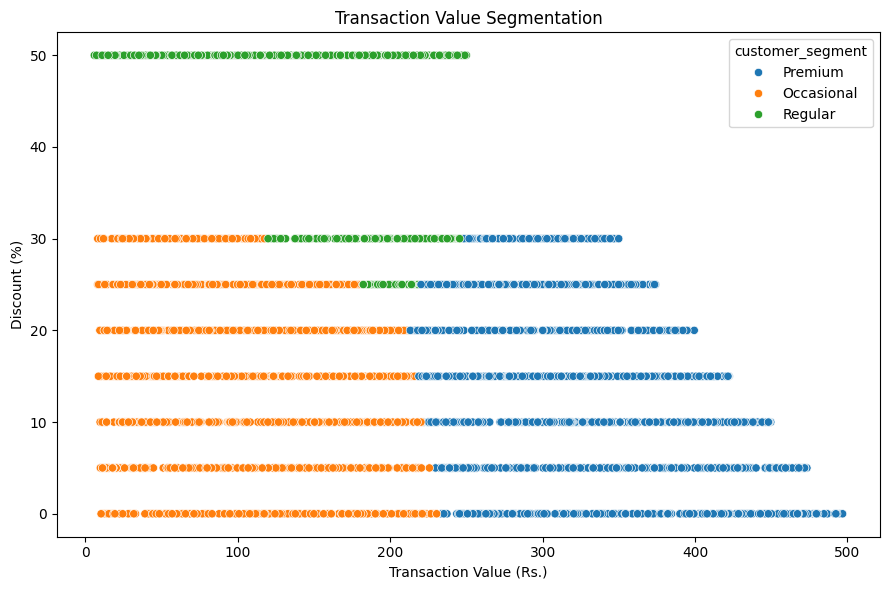

In [ ]:
# Visualize transaction-value segments
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=customer_df,
    x="total_spending",
    y="avg_discount",
    hue="customer_segment"
)
plt.title("Transaction Value Segmentation")
plt.xlabel("Transaction Value (Rs.)")
plt.ylabel("Discount (%)")
plt.tight_layout()
plt.show()

**MODEL OPTIMIZATION AND VALIDATION**
- **Ridge Regression:** GridSearchCV selects the regularization strength using 5-fold cross-validation on training data. Final metrics are calculated on a separate, later-dated test set.
- **K-Means:** Silhouette Score compares cluster counts from 2 to 5; three groups are retained to match the project brief.
- **KNN:** Uses scaled features and nearest-neighbour distance to retrieve similar records. Recommendation accuracy cannot be measured without relevance labels or customer feedback.

No purchase-probability model is reported because the dataset has no non-purchase examples.

In [ ]:
# Compare K-Means cluster counts using Silhouette Score
silhouette_results = []

for k in [2, 3, 4, 5]:
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = candidate.fit_predict(cluster_scaled)
    silhouette_results.append({
        "clusters": k,
        "silhouette_score": silhouette_score(cluster_scaled, labels)
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df)

score_3 = silhouette_df.loc[
    silhouette_df["clusters"] == 3, "silhouette_score"
].iloc[0]
print("Silhouette Score for the selected 3-cluster solution:", round(score_3, 4))

,clusters,silhouette_score
0,2,0.426581
1,3,0.438242
2,4,0.387030
3,5,0.367379


Silhouette Score for the selected 3-cluster solution: 0.4382


FINAL OUTPUTS

In [ ]:
# Display actual and estimated transaction prices
spending_results = X_test_lr.copy()
spending_results["Actual_Final_Price"] = y_test_lr.values
spending_results["Estimated_Final_Price"] = y_pred
display(spending_results.head(20))

,Price (Rs.),Discount (%),Category,Payment_Method,Month,Actual_Final_Price,Estimated_Final_Price
492,426.27,15,Books,Cash on Delivery,9,362.33,354.431798
1925,26.92,20,Home & Kitchen,UPI,9,21.54,19.812547
981,329.78,10,Beauty,Debit Card,9,296.80,290.418904
3410,93.82,5,Beauty,Net Banking,9,89.13,112.940429
286,260.74,5,Toys,Net Banking,9,247.70,247.887417
852,422.70,0,Toys,Debit Card,9,422.70,391.203175
1226,343.35,20,Toys,Credit Card,9,274.68,276.935996
3555,395.72,20,Electronics,Cash on Delivery,9,316.58,317.024883
1954,436.44,10,Books,UPI,9,392.80,374.334276
2436,103.44,30,Clothing,Debit Card,9,72.41,56.254538


In [ ]:
# Display transaction-value segments
final_segments = customer_df[
    ["User_ID", "total_spending", "avg_product_price",
     "avg_discount", "customer_segment"]
]
display(final_segments.head(20))

,User_ID,total_spending,avg_product_price,avg_discount,customer_segment
0,001ae40d,345.93,432.41,20.0,Premium
1,00209791,10.32,12.14,15.0,Occasional
2,0021e458,123.51,145.31,15.0,Occasional
3,00333c7a,8.65,11.54,25.0,Occasional
4,00390cf5,96.32,137.60,30.0,Occasional
5,0041710c,388.45,408.90,5.0,Premium
6,0049cde2,147.36,173.36,15.0,Occasional
7,005258a0,303.14,303.14,0.0,Premium
8,007d82ed,393.59,463.05,15.0,Premium
9,00812bf1,192.83,214.26,10.0,Occasional


In [ ]:
# Save estimated transaction prices and transaction-value segments
spending_results.to_csv("estimated_transaction_prices.csv", index=False)
final_segments.to_csv("transaction_value_segments.csv", index=False)

print("Estimated transaction prices and segment results saved successfully.")

Estimated transaction prices and segment results saved successfully.


In [ ]:
# Final Project Summary
print("=" * 55)
print("       E-COMMERCE CUSTOMER ANALYTICS")
print("=" * 55)

print("\n1. TRANSACTION PRICE ESTIMATION")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

print("\n2. SIMILAR-ITEM RECOMMENDATION")
print("Records available:", len(product_df))
print("Method: KNN on scaled transaction/product attributes")

print("\n3. K-MEANS SEGMENTATION")
print("Number of groups:", 3)
print("Silhouette Score:", round(score_3, 4))
print(customer_df["customer_segment"].value_counts())

print("\nNote: Purchase probability and future customer spending")
print("cannot be validated from the available one-transaction-per-user data.")
print("=" * 55)

       E-COMMERCE CUSTOMER ANALYTICS

1. TRANSACTION PRICE ESTIMATION
MAE : 14.73
RMSE: 21.15
R²  : 0.9701

2. SIMILAR-ITEM RECOMMENDATION
Records available: 3660
Method: KNN on scaled transaction/product attributes

3. K-MEANS SEGMENTATION
Number of groups: 3
Silhouette Score: 0.4382
customer_segment
Premium       1529
Occasional    1489
Regular        642
Name: count, dtype: int64

Note: Purchase probability and future customer spending
cannot be validated from the available one-transaction-per-user data.


**Conclusion**

The project analyses 3,660 e-commerce transactions through data preprocessing, exploratory analysis and machine learning. Ridge Regression estimates transaction final prices, KNN retrieves similar product/transaction records, and K-Means groups records into three transaction-value segments. Regression parameters are tuned with 5-fold cross-validation, while the K-Means cluster count is compared using Silhouette Score.

The dataset contains only one completed transaction per user and has no demographics, browsing history, product ratings or non-purchase examples. Therefore, it cannot support validated future customer-spending forecasts, purchase-probability prediction, personalised recommendations or repeat-customer segmentation. These functions require additional customer and interaction data.